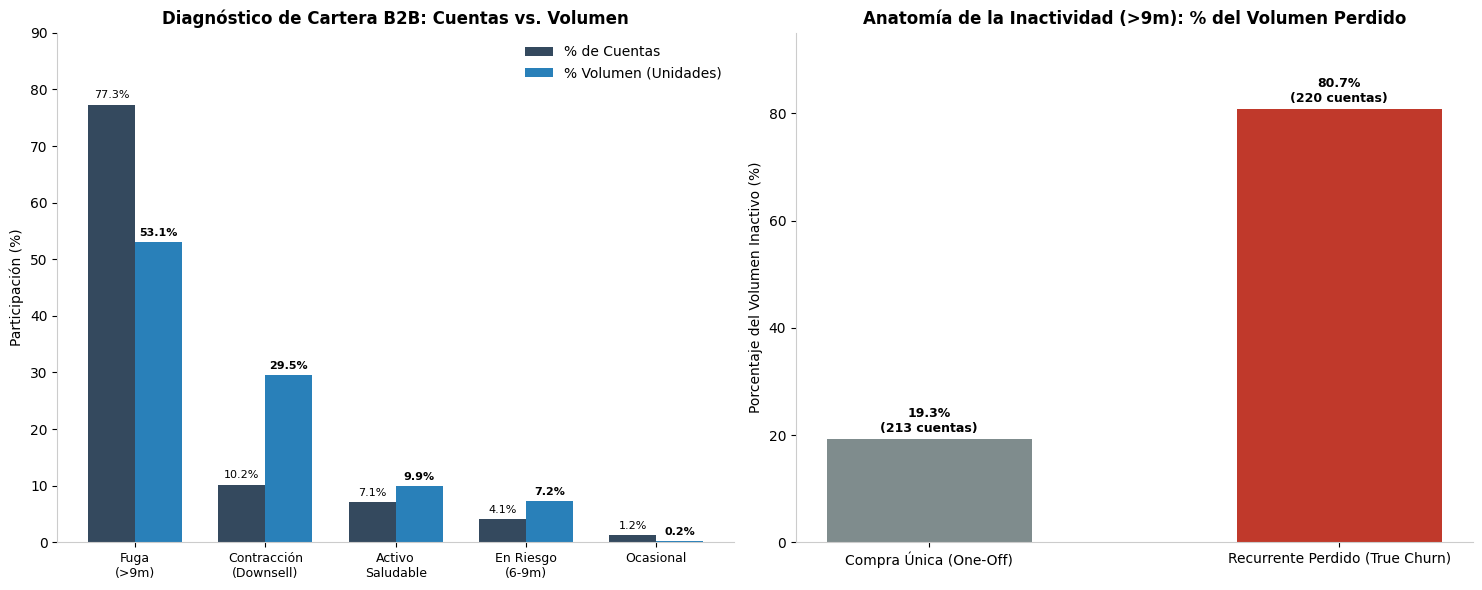

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

# Configuración estética
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

# 1. Carga de la base y copia de trabajo
df = pd.read_csv('dataset_b2b_vestuario_anonimizado.csv')
df_cartera = df.copy()
df_cartera['fecha_ingreso'] = pd.to_datetime(df_cartera['fecha_ingreso'])
fecha_corte = df_cartera['fecha_ingreso'].max()

# 2. Cálculo del Tiempo Medio Entre Pedidos (TBO) por cliente y sector
pedidos = df_cartera[['rut', 'sector_economico_ciiu', 'pedido', 'fecha_ingreso']].drop_duplicates()
pedidos = pedidos.sort_values(by=['rut', 'fecha_ingreso'])
pedidos['fecha_anterior'] = pedidos.groupby('rut')['fecha_ingreso'].shift(1)
pedidos['dias_entre_pedidos'] = (pedidos['fecha_ingreso'] - pedidos['fecha_anterior']).dt.days

tbo_cli = pedidos.groupby('rut')['dias_entre_pedidos'].agg(tbo_mediana='median').reset_index()
tbo_sector = pedidos.dropna(subset=['dias_entre_pedidos']).groupby('sector_economico_ciiu')['dias_entre_pedidos'].median().to_dict()
mediana_global = pedidos['dias_entre_pedidos'].median()

# 3. Consolidación histórica por cuenta B2B
resumen_cli = df_cartera.groupby(['rut', 'razon social', 'sector_economico_ciiu']).agg(
    total_unidades=('cantidad pedida', 'sum'),
    total_pedidos=('pedido', 'nunique'),
    primera_compra=('fecha_ingreso', 'min'),
    ultima_compra=('fecha_ingreso', 'max')
).reset_index()

resumen_cli = pd.merge(resumen_cli, tbo_cli, on='rut', how='left')
resumen_cli['tbo_referencia'] = (
    resumen_cli['tbo_mediana']
    .fillna(resumen_cli['sector_economico_ciiu'].map(tbo_sector))
    .fillna(mediana_global)
)
resumen_cli['recencia_dias'] = (fecha_corte - resumen_cli['ultima_compra']).dt.days

# 4. Detección de Contracción (Downsell): último pedido vs. promedio histórico previo
ordenes_vol = df_cartera.groupby(['rut', 'pedido', 'fecha_ingreso'])['cantidad pedida'].sum().reset_index()
ordenes_vol = ordenes_vol.sort_values(by=['rut', 'fecha_ingreso'])
ordenes_vol['orden_num'] = ordenes_vol.groupby('rut').cumcount() + 1
ordenes_vol['total_ordenes_cli'] = ordenes_vol.groupby('rut')['pedido'].transform('count')

ultimo_ped = ordenes_vol[ordenes_vol['orden_num'] == ordenes_vol['total_ordenes_cli']][['rut', 'cantidad pedida']].rename(
    columns={'cantidad pedida': 'unidades_ultimo_pedido'}
)
previos_multi = ordenes_vol[ordenes_vol['orden_num'] < ordenes_vol['total_ordenes_cli']].groupby('rut')['cantidad pedida'].mean().reset_index().rename(
    columns={'cantidad pedida': 'unidades_promedio_previas'}
)

resumen_cli = pd.merge(resumen_cli, ultimo_ped, on='rut')
resumen_cli = pd.merge(resumen_cli, previos_multi, on='rut', how='left')
resumen_cli['unidades_promedio_previas'] = resumen_cli['unidades_promedio_previas'].fillna(resumen_cli['unidades_ultimo_pedido'])
resumen_cli['var_pct_volumen'] = (
    (resumen_cli['unidades_ultimo_pedido'] - resumen_cli['unidades_promedio_previas']) /
    resumen_cli['unidades_promedio_previas']
) * 100

# 5. Reglas de negocio KAM para clasificación de salud de cartera
def diagnosticar_cartera(row):
    rec = row['recencia_dias']
    tbo = row['tbo_referencia']
    var = row['var_pct_volumen']
    ped = row['total_pedidos']
    
    if rec > 270 or (rec > 180 and rec > tbo * 3):
        return 'Fuga Confirmada (Churn > 9m)'
    elif rec > 180:
        return 'En Riesgo de Fuga (6-9m sin compra)'
    else:
        if ped > 1 and var <= -35.0:
            return 'Contracción de Presupuesto (Downsell Activo)'
        elif ped == 1 and rec > 90:
            return 'Ocasional / En Observación'
        else:
            return 'Activo y Saludable'

resumen_cli['estado_cartera'] = resumen_cli.apply(diagnosticar_cartera, axis=1)

# 6. Anatomía de la Fuga Confirmada: Compra Única vs. Recurrente Perdido (True Churn)
resumen_cli['subtipo_fuga'] = np.where(
    resumen_cli['estado_cartera'] != 'Fuga Confirmada (Churn > 9m)',
    'No aplica',
    np.where(resumen_cli['total_pedidos'] == 1, 'Compra Única (One-Off)', 'Recurrente Perdido (True Churn)')
)

# 7. Tablas de síntesis ejecutiva
tabla_resumen = resumen_cli.groupby('estado_cartera').agg(
    cuentas=('rut', 'count'),
    unidades_totales=('total_unidades', 'sum'),
    recencia_media=('recencia_dias', 'mean'),
    pedidos_totales=('total_pedidos', 'sum')
).reset_index()

tabla_resumen['pct_cuentas'] = (tabla_resumen['cuentas'] / len(resumen_cli)) * 100
tabla_resumen['pct_unidades'] = (tabla_resumen['unidades_totales'] / resumen_cli['total_unidades'].sum()) * 100
tabla_resumen = tabla_resumen.sort_values(by='unidades_totales', ascending=False)

subtipo_churn = resumen_cli[resumen_cli['estado_cartera'] == 'Fuga Confirmada (Churn > 9m)'].groupby('subtipo_fuga').agg(
    cuentas=('rut', 'count'),
    unidades=('total_unidades', 'sum'),
    pedidos=('total_pedidos', 'sum'),
    recencia_media=('recencia_dias', 'mean')
).reset_index()
subtipo_churn['pct_cuentas_churn'] = (subtipo_churn['cuentas'] / subtipo_churn['cuentas'].sum()) * 100
subtipo_churn['pct_unidades_churn'] = (subtipo_churn['unidades'] / subtipo_churn['unidades'].sum()) * 100

# 8. Visualización Ejecutiva (2 Paneles exportables en alta resolución para LinkedIn)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

orden_estados = [
    'Fuga Confirmada (Churn > 9m)',
    'Contracción de Presupuesto (Downsell Activo)',
    'Activo y Saludable',
    'En Riesgo de Fuga (6-9m sin compra)',
    'Ocasional / En Observación'
]
colores_estados = ['#C0392B', '#E67E22', '#27AE60', '#F1C40F', '#95A5A6']

df_plot = tabla_resumen.set_index('estado_cartera').loc[orden_estados].reset_index()

# Panel A: Participación en Cuentas vs. Volumen Histórico
x = np.arange(len(df_plot))
width = 0.36
rects1 = axes[0].bar(x - width/2, df_plot['pct_cuentas'], width, label='% de Cuentas', color='#34495E')
rects2 = axes[0].bar(x + width/2, df_plot['pct_unidades'], width, label='% Volumen (Unidades)', color='#2980B9')

axes[0].set_title('Diagnóstico de Cartera B2B: Cuentas vs. Volumen', fontweight='bold', fontsize=12)
axes[0].set_xticks(x)
axes[0].set_xticklabels(['Fuga\n(>9m)', 'Contracción\n(Downsell)', 'Activo\nSaludable', 'En Riesgo\n(6-9m)', 'Ocasional'], fontsize=9)
axes[0].set_ylabel('Participación (%)')
axes[0].set_ylim(0, 90)
axes[0].legend(frameon=False)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

for rect in rects1:
    h = rect.get_height()
    axes[0].annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                     textcoords="offset points", ha='center', va='bottom', fontsize=8)
for rect in rects2:
    h = rect.get_height()
    axes[0].annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                     textcoords="offset points", ha='center', va='bottom', fontsize=8, fontweight='bold')

# Panel B: Anatomía de la Fuga Confirmada (One-Off vs. True Churn)
axes[1].bar(
    subtipo_churn['subtipo_fuga'],
    subtipo_churn['pct_unidades_churn'],
    color=['#7F8C8D', '#C0392B'],
    width=0.5
)
axes[1].set_title('Anatomía de la Inactividad (>9m): % del Volumen Perdido', fontweight='bold', fontsize=12)
axes[1].set_ylabel('Porcentaje del Volumen Inactivo (%)')
axes[1].set_ylim(0, 95)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

for i, row in subtipo_churn.iterrows():
    axes[1].annotate(
        f"{row['pct_unidades_churn']:.1f}%\n({row['cuentas']} cuentas)",
        xy=(i, row['pct_unidades_churn']),
        xytext=(0, 5),
        textcoords="offset points",
        ha='center',
        fontweight='bold',
        fontsize=9
    )

plt.tight_layout()
plt.savefig('caso1_salud_cartera_b2b.png', dpi=300, bbox_inches='tight')
plt.show()

# Exportar resumen para alimentar Power BI (Pestaña 1)
resumen_cli.to_csv('pbi_pestana1_salud_cartera.csv', index=False, encoding='utf-8-sig')

In [2]:
texto_analisis_caso1 = """
## 📊 Diagnóstico de Salud de Cartera B2B: Fuga Silenciosa vs. Contracción de Presupuesto

**Alcance Metodológico:** El estudio evalúa el comportamiento transversal de **560 cuentas B2B** de distribución mayorista recurrente (**1.967 órdenes** y **83.381 unidades** normalizadas al corte del 29-07-2026), excluyendo contratos especiales de confección a medida para modelar sin distorsiones de escala la dinámica real de retención del portafolio estándar.

---

### 1. El Fenómeno Oculto: Contracción de Presupuesto (*Downsell* Activo)
* **57 cuentas (10,2% de la cartera)** se encuentran operando bajo contracción severa de volumen.
* **Peso estratégico:** Concentran **24.633 unidades** (**29,5% del volumen histórico total**), casi tres veces más que el segmento saludable.
* **Comportamiento:** Presentan una recencia promedio de **66,8 días** (siguen comprando activamente), pero su última orden cayó más de un **35% (con casos superiores al -90%)** frente a su promedio histórico.
* **Cuentas emblemáticas en contracción:**
  * **`CLI_0177`** *(Transporte y Almacenamiento)*: 2.831 u. históricas; cayó de un promedio de 141 u./orden a 10 u. (**-92,9%**), con compra hace 37 días.
  * **`CLI_0202`** *(Comunidades y Edificios)*: 2.759 u. históricas; cayó de 81 u./orden a 4 u. (**-95,1%**), con compra hace 6 días.
  * **`CLI_0097`** *(Inmobiliaria y Financiera)*: 2.514 u. históricas; cayó de 179 u./orden a 10 u. (**-94,4%**), con compra hace 37 días.
  * **`CLI_0526`** *(Construcción)*: 2.172 u. históricas; cayó de 102 u./orden a 34 u. (**-66,6%**).

---

### 2. Ventana Crítica de Intervención: Cartera en Riesgo (6 a 9 Meses)
* **23 cuentas (4,1% de la cartera)** acumulan entre 180 y 270 días sin emitir órdenes (recencia media de **235,0 días**), comprometiendo **6.045 unidades (7,2% del portafolio)**.
* Representan el foco inmediato de rescate comercial antes de que crucen el umbral de abandono definitivo.

---

### 3. Anatomía de la Inactividad (>9 Meses): *One-Off* vs. *True Churn*
Aunque **433 cuentas (77,3%)** superan los 9 meses sin compras (**44.240 unidades**, 53,1% del total), desagregarlas revela dos fenómenos distintos:
* **Compra Única (*One-Off*): 213 cuentas (49,2% de los inactivos)** compraron solo una vez y representan apenas el **19,3% del volumen inactivo (8.529 u.)**, con recencia media de 732,6 días. Responden a eventos puntuales (aperturas, eventos corporativos).
* **Recurrente Perdido (*True Churn*): 220 cuentas (50,8% de los inactivos)** tenían historial de recompra (917 órdenes previas) y concentran el **80,7% del daño volumétrico por fuga (35.711 u.)**. Destacan cuentas de alto valor como **`CLI_0336`** (Manufactura Alimenticia, 5.101 u., 32 pedidos, TBO de 5 días, 433 días inactiva) y **`CLI_0365`** (2.348 u., 13 pedidos, 558 días inactiva).

---

### Cuadro Resumen Consolidado

| Estado de Cartera | Cuentas | % Cuentas | Unidades Totales | % Volumen | Recencia Media | Órdenes Totales |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Fuga Confirmada (Churn > 9m)** | 433 | 77,3% | 44.240 | 53,1% | 674,6 días | 1.130 |
| **Contracción de Presupuesto (Downsell)** | 57 | 10,2% | 24.633 | 29,5% | 66,8 días | 546 |
| **Activo y Saludable** | 40 | 7,1% | 8.288 | 9,9% | 66,5 días | 205 |
| **En Riesgo de Fuga (6-9m sin compra)** | 23 | 4,1% | 6.045 | 7,2% | 235,0 días | 79 |
| **Ocasional / En Observación** | 7 | 1,3% | 175 | 0,2% | 128,3 días | 7 |
| **Total Portafolio Analizado** | **560** | **100,0%** | **83.381** | **100,0%** | **544,2 días** | **1.967** |
"""

display(Markdown(texto_analisis_caso1))


## 📊 Diagnóstico de Salud de Cartera B2B: Fuga Silenciosa vs. Contracción de Presupuesto

**Alcance Metodológico:** El estudio evalúa el comportamiento transversal de **560 cuentas B2B** de distribución mayorista recurrente (**1.967 órdenes** y **83.381 unidades** normalizadas al corte del 29-07-2026), excluyendo contratos especiales de confección a medida para modelar sin distorsiones de escala la dinámica real de retención del portafolio estándar.

---

### 1. El Fenómeno Oculto: Contracción de Presupuesto (*Downsell* Activo)
* **57 cuentas (10,2% de la cartera)** se encuentran operando bajo contracción severa de volumen.
* **Peso estratégico:** Concentran **24.633 unidades** (**29,5% del volumen histórico total**), casi tres veces más que el segmento saludable.
* **Comportamiento:** Presentan una recencia promedio de **66,8 días** (siguen comprando activamente), pero su última orden cayó más de un **35% (con casos superiores al -90%)** frente a su promedio histórico.
* **Cuentas emblemáticas en contracción:**
  * **`CLI_0177`** *(Transporte y Almacenamiento)*: 2.831 u. históricas; cayó de un promedio de 141 u./orden a 10 u. (**-92,9%**), con compra hace 37 días.
  * **`CLI_0202`** *(Comunidades y Edificios)*: 2.759 u. históricas; cayó de 81 u./orden a 4 u. (**-95,1%**), con compra hace 6 días.
  * **`CLI_0097`** *(Inmobiliaria y Financiera)*: 2.514 u. históricas; cayó de 179 u./orden a 10 u. (**-94,4%**), con compra hace 37 días.
  * **`CLI_0526`** *(Construcción)*: 2.172 u. históricas; cayó de 102 u./orden a 34 u. (**-66,6%**).

---

### 2. Ventana Crítica de Intervención: Cartera en Riesgo (6 a 9 Meses)
* **23 cuentas (4,1% de la cartera)** acumulan entre 180 y 270 días sin emitir órdenes (recencia media de **235,0 días**), comprometiendo **6.045 unidades (7,2% del portafolio)**.
* Representan el foco inmediato de rescate comercial antes de que crucen el umbral de abandono definitivo.

---

### 3. Anatomía de la Inactividad (>9 Meses): *One-Off* vs. *True Churn*
Aunque **433 cuentas (77,3%)** superan los 9 meses sin compras (**44.240 unidades**, 53,1% del total), desagregarlas revela dos fenómenos distintos:
* **Compra Única (*One-Off*): 213 cuentas (49,2% de los inactivos)** compraron solo una vez y representan apenas el **19,3% del volumen inactivo (8.529 u.)**, con recencia media de 732,6 días. Responden a eventos puntuales (aperturas, eventos corporativos).
* **Recurrente Perdido (*True Churn*): 220 cuentas (50,8% de los inactivos)** tenían historial de recompra (917 órdenes previas) y concentran el **80,7% del daño volumétrico por fuga (35.711 u.)**. Destacan cuentas de alto valor como **`CLI_0336`** (Manufactura Alimenticia, 5.101 u., 32 pedidos, TBO de 5 días, 433 días inactiva) y **`CLI_0365`** (2.348 u., 13 pedidos, 558 días inactiva).

---

### Cuadro Resumen Consolidado

| Estado de Cartera | Cuentas | % Cuentas | Unidades Totales | % Volumen | Recencia Media | Órdenes Totales |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Fuga Confirmada (Churn > 9m)** | 433 | 77,3% | 44.240 | 53,1% | 674,6 días | 1.130 |
| **Contracción de Presupuesto (Downsell)** | 57 | 10,2% | 24.633 | 29,5% | 66,8 días | 546 |
| **Activo y Saludable** | 40 | 7,1% | 8.288 | 9,9% | 66,5 días | 205 |
| **En Riesgo de Fuga (6-9m sin compra)** | 23 | 4,1% | 6.045 | 7,2% | 235,0 días | 79 |
| **Ocasional / En Observación** | 7 | 1,3% | 175 | 0,2% | 128,3 días | 7 |
| **Total Portafolio Analizado** | **560** | **100,0%** | **83.381** | **100,0%** | **544,2 días** | **1.967** |


In [7]:
estrategia_ejecutivo = """
## 🎯 Plan de Acción Comercial (Perspectiva Ejecutivo de Cuentas B2B)

Tratar toda caída de pedidos como un problema genérico de "pérdida de clientes" desgasta el tiempo de gestión y desenfoca la prospección. Desde la gestión directa de cartera como **Ejecutivo de Cuentas B2B**, el abordaje se divide en **tres frentes tácticos de ejecución anual**:

### 1. Diagnóstico Consultivo de Dotación para las 57 Cuentas en *Downsell* Activo
* **Lectura comercial:** Cuando un cliente recurrente como `CLI_0177` o `CLI_0202` mantiene compras frecuentes (cada 6 a 37 días) pero reduce su orden de ~140 unidades a 4–10 unidades, **la cuenta sigue activa, pero está comprando solo reposiciones de emergencia por rotación de personal** y postergando su renovación masiva (o dividiendo pedidos con otro proveedor).
* **Acción del Ejecutivo:** Agendar una reunión de revisión comercial con el encargado de Adquisiciones o Prevención de Riesgos para levantar su calendario anual de recambio de uniformes, ofreciendo **cotizaciones escalonadas por volumen comprometido** y entregas programadas que cuiden su presupuesto sin ceder participación de compra (*Share of Wallet*).

### 2. Seguimiento Preventivo en CRM (*Trigger* a 120 Días) para las 23 Cuentas "En Riesgo"
* **Lectura comercial:** Contactar a una empresa B2B recién a los 270 días de inactividad es llegar tarde, cuando ya cerró la compra con un competidor.
* **Acción del Ejecutivo:** Configurar recordatorios de gestión en el CRM cuando una cuenta habitual supere **1,5 veces su ciclo promedio de recompra (TBO)** o alcance los 120–150 días sin cotizar, realizando un contacto consultivo con catálogo de temporada antes de que cruce la barrera crítica de los 6 meses.

### 3. Campaña de Reactivación Focalizada en los 220 Recurrentes Perdidos (*True Churn*)
* **Lectura comercial:** No conviene invertir horas de terreno ni llamadas en los 213 compradores de una sola vez (*One-Off*, asociados a eventos puntuales). El foco de recuperación debe concentrarse en el Top 30 de los **220 clientes que sí tenían historial de recompra** (como `CLI_0336` o `CLI_0365`).
* **Acción del Ejecutivo:** Ejecutar una ronda de contacto de recuperación (*Win-Back*) enfocada en detectar si hubo quiebres de stock o retrasos en sus últimos despachos, respaldada por una oferta de reactivación concreta (envío de muestrario físico y revisión de condiciones comerciales en su orden de retorno).
"""

display(Markdown(estrategia_ejecutivo))


## 🎯 Plan de Acción Comercial (Perspectiva Ejecutivo de Cuentas B2B)

Tratar toda caída de pedidos como un problema genérico de "pérdida de clientes" desgasta el tiempo de gestión y desenfoca la prospección. Desde la gestión directa de cartera como **Ejecutivo de Cuentas B2B**, el abordaje se divide en **tres frentes tácticos de ejecución anual**:

### 1. Diagnóstico Consultivo de Dotación para las 57 Cuentas en *Downsell* Activo
* **Lectura comercial:** Cuando un cliente recurrente como `CLI_0177` o `CLI_0202` mantiene compras frecuentes (cada 6 a 37 días) pero reduce su orden de ~140 unidades a 4–10 unidades, **la cuenta sigue activa, pero está comprando solo reposiciones de emergencia por rotación de personal** y postergando su renovación masiva (o dividiendo pedidos con otro proveedor).
* **Acción del Ejecutivo:** Agendar una reunión de revisión comercial con el encargado de Adquisiciones o Prevención de Riesgos para levantar su calendario anual de recambio de uniformes, ofreciendo **cotizaciones escalonadas por volumen comprometido** y entregas programadas que cuiden su presupuesto sin ceder participación de compra (*Share of Wallet*).

### 2. Seguimiento Preventivo en CRM (*Trigger* a 120 Días) para las 23 Cuentas "En Riesgo"
* **Lectura comercial:** Contactar a una empresa B2B recién a los 270 días de inactividad es llegar tarde, cuando ya cerró la compra con un competidor.
* **Acción del Ejecutivo:** Configurar recordatorios de gestión en el CRM cuando una cuenta habitual supere **1,5 veces su ciclo promedio de recompra (TBO)** o alcance los 120–150 días sin cotizar, realizando un contacto consultivo con catálogo de temporada antes de que cruce la barrera crítica de los 6 meses.

### 3. Campaña de Reactivación Focalizada en los 220 Recurrentes Perdidos (*True Churn*)
* **Lectura comercial:** No conviene invertir horas de terreno ni llamadas en los 213 compradores de una sola vez (*One-Off*, asociados a eventos puntuales). El foco de recuperación debe concentrarse en el Top 30 de los **220 clientes que sí tenían historial de recompra** (como `CLI_0336` o `CLI_0365`).
* **Acción del Ejecutivo:** Ejecutar una ronda de contacto de recuperación (*Win-Back*) enfocada en detectar si hubo quiebres de stock o retrasos en sus últimos despachos, respaldada por una oferta de reactivación concreta (envío de muestrario físico y revisión de condiciones comerciales en su orden de retorno).


In [8]:
texto_bibliografia = """
## 📚 Bibliografía y Referencias Metodológicas

* **Griffin, J., & Lowenstein, M. W. (2001).** *Customer WinBack: How to Recapture Lost Customers and Keep Them Loyal*. Jossey-Bass.  
  *(Metodología para diagnosticar causas de deserción en cuentas B2B y estructurar campañas de reactivación focalizadas en clientes recurrentes).*
* **Jobber, D., & Lancaster, G. (2015).** *Selling and Sales Management* (10th ed.). Pearson.  
  *(Fundamentos de gestión comercial B2B, administración de carteras por ejecutivos de cuentas y venta consultiva).*
* **Knaflic, C. N. (2015).** *Storytelling with Data: A Data Visualization Guide for Business Professionals*. Wiley.  
  *(Principios de diseño visual ejecutivo para comunicar hallazgos comerciales de forma clara y accionable).*
* **Mirza, B., & Patel, A. (2020).** *Data Science for Marketing Analytics: A Practical Guide to Forming a Killer Marketing Strategy Through Data Analysis with Python*. Packt Publishing.  
  *(Aplicación práctica en Python de segmentación RFM, cálculo de recencia e intervalos entre órdenes).*
* **Reinartz, W. J., & Kumar, V. (2002).** *The Mismanagement of Customer Loyalty*. Harvard Business Review, 80(7), 86–95.  
  *(Distinción empírica entre compradores transaccionales de una sola vez [One-Off] y clientes relacionales recurrentes para priorizar esfuerzos comerciales).*
* **Verhoef, P. C., Franses, P. H., & Hoekstra, J. C. (2001).** *The effect of customer relationship management efforts on customer retention and customer share development*. Journal of Marketing, 65(4), 89–99.  
  *(Marco analítico para diferenciar el abandono total de la cuenta frente a la contracción parcial del presupuesto o Share of Wallet).*
"""

display(Markdown(texto_bibliografia))


## 📚 Bibliografía y Referencias Metodológicas

* **Griffin, J., & Lowenstein, M. W. (2001).** *Customer WinBack: How to Recapture Lost Customers and Keep Them Loyal*. Jossey-Bass.  
  *(Metodología para diagnosticar causas de deserción en cuentas B2B y estructurar campañas de reactivación focalizadas en clientes recurrentes).*
* **Jobber, D., & Lancaster, G. (2015).** *Selling and Sales Management* (10th ed.). Pearson.  
  *(Fundamentos de gestión comercial B2B, administración de carteras por ejecutivos de cuentas y venta consultiva).*
* **Knaflic, C. N. (2015).** *Storytelling with Data: A Data Visualization Guide for Business Professionals*. Wiley.  
  *(Principios de diseño visual ejecutivo para comunicar hallazgos comerciales de forma clara y accionable).*
* **Mirza, B., & Patel, A. (2020).** *Data Science for Marketing Analytics: A Practical Guide to Forming a Killer Marketing Strategy Through Data Analysis with Python*. Packt Publishing.  
  *(Aplicación práctica en Python de segmentación RFM, cálculo de recencia e intervalos entre órdenes).*
* **Reinartz, W. J., & Kumar, V. (2002).** *The Mismanagement of Customer Loyalty*. Harvard Business Review, 80(7), 86–95.  
  *(Distinción empírica entre compradores transaccionales de una sola vez [One-Off] y clientes relacionales recurrentes para priorizar esfuerzos comerciales).*
* **Verhoef, P. C., Franses, P. H., & Hoekstra, J. C. (2001).** *The effect of customer relationship management efforts on customer retention and customer share development*. Journal of Marketing, 65(4), 89–99.  
  *(Marco analítico para diferenciar el abandono total de la cuenta frente a la contracción parcial del presupuesto o Share of Wallet).*
